# Transferência de vocabulário por ativações — Método A: bateria de validação

**Professor:** família `Qwen2.5` · **Receptor:** família `GPT-2` · **Objetivo:** inserir novos tokens no receptor, otimizando *apenas* o vetor de cada token novo, usando a assinatura de ativação do MLP do professor.

## Por que este notebook existe

No notebook anterior, as métricas (Recall@5 = 1.0 para `recall_surrogate` e `combined`) foram calculadas **nas mesmas âncoras usadas no treino**. Como cada vetor tem 768+ graus de liberdade e só ~36 restrições, ele consegue decorar o ranking: isso mede *ajuste*, não *transferência*. Este notebook troca essa avaliação por quatro experimentos, na ordem de prioridade da planilha:

| # | Experimento | Objetivo | Prioridade |
|---|---|---|---|
| 1 | Separar âncoras de treino e teste | Verificar generalização | **Muito alta** |
| 2 | Testar diferentes seeds | Verificar estabilidade | **Muito alta** |
| 3 | Testar novos contextos | Avaliar utilização funcional | Alta |
| 4 | Comparar camadas do MLP | Qual camada transfere melhor a semântica | Alta |

Todos os resultados vêm com **intervalo de confiança de 95%** (bootstrap em dois níveis: reamostra seeds *e* alvos) e comparações **pareadas** contra a baseline.

## Escala de modelagem (estilo EfficientNet)

Uma única variável, `MODEL_SCALE` (φ), escala o experimento inteiro de forma composta: tamanho do professor e do receptor (profundidade/largura), nº de alvos e âncoras (resolução dos dados), nº de templates, seeds e épocas. `MODEL_SCALE = "auto"` escolhe o maior φ que cabe na GPU detectada.

| Hardware | φ recomendado | φ máximo (por estimativa) |
|---|---|---|
| T4 16 GB | **3** (`auto` escolhe 3) | 3 |
| A100 40 GB | **4** (`auto` escolhe 4) | 5 (apertado) |
| A100 80 GB | **5** | 5 |

> Os requisitos de VRAM são **estimativas** (parâmetros × bytes + margem), não medições.

## Mudanças em relação ao notebook anterior (todas configuráveis)

- **Centralização** das assinaturas do professor e dos embeddings do receptor (`CENTER_SPACES`): as saídas do MLP final têm um componente comum enorme, que faz todos os cossenos ficarem ≈ 1 e esconde a estrutura semântica.
- **Padronização (z-score)** das similaridades na loss de cosseno (`STANDARDIZE_RELATIONS`): comparar valores brutos de cosseno entre espaços diferentes não tem significado; a ordem e a forma relativa têm.
- **Âncoras com espaço inicial** (`" plant"`, não `"plant"`), que é como o GPT-2 vê palavras no meio de frases.
- **Norma preservada na inserção**: a loss só fixa a *direção*; a escala do vetor final é a da inicialização. Sem isso o token novo pode ter norma arbitrária e dominar (ou sumir de) logits e atenção.
- Os tokens novos são inseridos **por id**, sem `add_tokens`, evitando o subtoken espúrio de espaço que o tokenizador gera antes de tokens adicionados.
- nDCG com relevância deslocada para ≥ 0 (cossenos podem ser negativos depois da centralização). Os valores **não são comparáveis** com os do CSV antigo.

## 0. Ambiente

In [ ]:
!pip -q install -U "transformers>=4.45,<5" accelerate scipy scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import os, gc, math, random, time, itertools, json, warnings
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import rankdata
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    major, _ = torch.cuda.get_device_capability(0)
    # T4 (sm_75) não tem bf16 nativo; is_bf16_supported() pode devolver True por emulação lenta.
    DTYPE = torch.bfloat16 if major >= 8 else torch.float16
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
else:
    DTYPE, GPU_NAME, GPU_GB = torch.float32, "CPU", 0.0
print(f"Device: {GPU_NAME} | VRAM: {GPU_GB:.1f} GB | dtype: {DTYPE} | torch {torch.__version__}")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: NVIDIA A100-SXM4-80GB | VRAM: 85.1 GB | dtype: torch.bfloat16 | torch 2.14.1+cu130


## 1. Variável de escala de modelagem (φ)

`MODEL_SCALE` é **a única variável que você precisa mexer**. Como na EfficientNet, ela escala várias dimensões juntas:

- **Profundidade/largura:** par professor/receptor sobe numa escada (Qwen2.5 0.5B→14B, GPT-2 small→XL). Essa dimensão é discreta, não exponencial.
- **Resolução dos dados:** `n = base × α^φ` para alvos (α=1.35), âncoras (1.15) e templates (1.12).
- **Poder estatístico:** seeds `3 × 1.25^φ` e épocas `120 + 20φ`.

Se quiser forçar algum valor, use `OVERRIDES`, por exemplo `{"n_seeds": 10}`. Com poucas seeds (φ=0 usa 3) o IC por bootstrap é pouco confiável.

In [ ]:
MODEL_SCALE = 5      # inteiro 0..5  ou  "auto"  (maior φ que cabe na GPU, com 20% de folga)
OVERRIDES = {}            # ex.: {"n_seeds": 10, "n_targets": 12}

# (professor, receptor, params professor [B], params receptor [B])
LADDER = [
    ("Qwen/Qwen2.5-0.5B", "openai-community/gpt2",        0.494, 0.124),  # φ0  CPU / teste rápido
    ("Qwen/Qwen2.5-0.5B", "openai-community/gpt2-medium", 0.494, 0.355),  # φ1
    ("Qwen/Qwen2.5-1.5B", "openai-community/gpt2-medium", 1.54,  0.355),  # φ2
    ("Qwen/Qwen2.5-3B",   "openai-community/gpt2-large",  3.09,  0.774),  # φ3  teto da T4
    ("Qwen/Qwen2.5-7B",   "openai-community/gpt2-xl",     7.62,  1.558),  # φ4  A100 40 GB
    ("Qwen/Qwen2.5-14B",  "openai-community/gpt2-xl",     14.77, 1.558),  # φ5  A100 80 GB (40 GB apertado)
]
BASE   = dict(n_targets=8, n_anchors=860, n_train_templates=4, n_seeds=3, epochs=120)
GROWTH = dict(n_targets=1.35, n_anchors=1.01, n_train_templates=1.12, n_seeds=1.25)
EPOCH_STEP = 20
OVERHEAD_GB = 2.0          # contexto CUDA + ativações + logits dos testes funcionais
VRAM_HEADROOM = 0.80       # só usa até 80% da VRAM total

@dataclass
class ScaleConfig:
    phi: int
    teacher_id: str
    student_id: str
    n_targets: int
    n_anchors: int
    n_train_templates: int
    n_seeds: int
    epochs: int
    est_vram_gb: float

def est_vram_gb(phi):
    _, _, pt, ps = LADDER[phi]
    bytes_per_param = 2 if DTYPE != torch.float32 else 4
    return bytes_per_param * (pt + ps) + OVERHEAD_GB

def make_config(phi):
    t_id, s_id, _, _ = LADDER[phi]
    v = {k: int(round(BASE[k] * GROWTH[k] ** phi)) for k in GROWTH}
    v["epochs"] = BASE["epochs"] + EPOCH_STEP * phi
    cfg = ScaleConfig(phi, t_id, s_id, est_vram_gb=round(est_vram_gb(phi), 1), **v)
    for k, val in OVERRIDES.items():
        setattr(cfg, k, val)
    return cfg

def pick_phi():
    if DEVICE.type != "cuda":
        return 0
    best = 0
    for p in range(len(LADDER)):
        if est_vram_gb(p) <= VRAM_HEADROOM * GPU_GB:
            best = p
    return best

PHI = pick_phi() if MODEL_SCALE == "auto" else int(MODEL_SCALE)
assert 0 <= PHI < len(LADDER), f"MODEL_SCALE deve estar em 0..{len(LADDER)-1}"
cfg = make_config(PHI)

ladder_df = pd.DataFrame([asdict(make_config(p)) for p in range(len(LADDER))])
for name, gb in [("T4", 15.8), ("A100-40", 42.5), ("A100-80", 85.0)]:
    ladder_df[f"cabe_{name}"] = ladder_df.est_vram_gb <= VRAM_HEADROOM * gb
display(ladder_df)
print(f"\n>>> φ escolhido = {PHI}  |  {cfg}")
if cfg.est_vram_gb > VRAM_HEADROOM * max(GPU_GB, 1e-9) and DEVICE.type == "cuda":
    print(f"AVISO: estimativa {cfg.est_vram_gb} GB > {VRAM_HEADROOM:.0%} de {GPU_GB:.1f} GB. Reduza MODEL_SCALE.")

,phi,teacher_id,student_id,n_targets,n_anchors,n_train_templates,n_seeds,epochs,est_vram_gb,cabe_T4,cabe_A100-40,cabe_A100-80
0,0,Qwen/Qwen2.5-0.5B,openai-community/gpt2,8,860,4,3,120,3.2,True,True,True
1,1,Qwen/Qwen2.5-0.5B,openai-community/gpt2-medium,11,869,4,4,140,3.7,True,True,True
2,2,Qwen/Qwen2.5-1.5B,openai-community/gpt2-medium,15,877,5,5,160,5.8,True,True,True
3,3,Qwen/Qwen2.5-3B,openai-community/gpt2-large,20,886,6,6,180,9.7,True,True,True
4,4,Qwen/Qwen2.5-7B,openai-community/gpt2-xl,27,895,6,7,200,20.4,False,True,True
5,5,Qwen/Qwen2.5-14B,openai-community/gpt2-xl,36,904,7,9,220,34.7,False,False,True



>>> φ escolhido = 5  |  ScaleConfig(phi=5, teacher_id='Qwen/Qwen2.5-14B', student_id='openai-community/gpt2-xl', n_targets=36, n_anchors=904, n_train_templates=7, n_seeds=9, epochs=220, est_vram_gb=34.7)


## 2. Configuração experimental

Os pools abaixo são ordenados: os **8 alvos e as 36 âncoras originais vêm primeiro**, então φ pequeno reproduz o notebook anterior. Cada palavra tem *domínios* (`bio`, `chem`, `phys`, `astro`, `earth`, `med`, `neuro`).

- **Gold independente:** `gold[alvo, âncora] = nº de domínios em comum`. Ele não depende de nenhum modelo e serve de régua para comparar camadas (Exp. 4) sem circularidade. É **grosseiro e escrito por mim**: revise os domínios se for usar em resultado de publicação.
- **Glosses:** definição curta de cada alvo, usada só no teste funcional (Exp. 3). O vetor nunca vê esses textos no treino.
- **Templates:** de treino (palavra no fim da frase) e **de contextos novos** (palavra no meio), nunca usados no treino.

In [ ]:
# (palavra, domínios, gloss) — alvos; os 8 primeiros são os do notebook original
TARGET_POOL = [
    ("photosynthesis", {"bio","chem"}, "is the process by which plants use sunlight to turn water and carbon dioxide into sugar and oxygen"),
    ("bioluminescence", {"bio"}, "is the emission of light by living organisms such as fireflies and deep-sea fish"),
    ("thermodynamics", {"phys"}, "is the branch of physics that studies heat, energy, and work"),
    ("electroencephalography", {"neuro","med"}, "is a method of recording the electrical activity of the brain using electrodes on the scalp"),
    ("quasar", {"astro"}, "is an extremely bright and distant galactic nucleus powered by a supermassive black hole"),
    ("mitochondrion", {"bio"}, "is the organelle in a cell that produces most of its chemical energy"),
    ("photosensitive", {"phys","bio"}, "describes a material or organ that reacts to light"),
    ("geothermal", {"earth","phys"}, "describes energy or heat that comes from inside the Earth"),
    ("spectroscopy", {"phys","chem","astro"}, "is the study of how matter interacts with light across different wavelengths"),
    ("chromatography", {"chem"}, "is a laboratory technique for separating the components of a mixture"),
    ("neurotransmitter", {"neuro","bio","med"}, "is a chemical messenger that carries signals between nerve cells"),
    ("photovoltaic", {"phys"}, "describes devices that convert sunlight directly into electricity"),
    ("seismology", {"earth","phys"}, "is the scientific study of earthquakes and the waves they send through the Earth"),
    ("supernova", {"astro","phys"}, "is the explosion of a massive star at the end of its life"),
    ("exoplanet", {"astro"}, "is a planet that orbits a star outside our solar system"),
    ("chlorophyll", {"bio","chem"}, "is the green pigment in plants that absorbs light for photosynthesis"),
    ("endothermic", {"chem","phys"}, "describes a reaction that absorbs heat from its surroundings"),
    ("electrolysis", {"chem","phys"}, "is a process that uses electric current to drive a chemical reaction such as splitting water"),
    ("neuroplasticity", {"neuro","bio"}, "is the ability of the brain to reorganize itself by forming new connections"),
    ("tectonics", {"earth"}, "is the study of the large-scale movement of the plates of the Earth's crust"),
    ("magnetosphere", {"astro","earth","phys"}, "is the region around a planet dominated by its magnetic field"),
    ("nucleotide", {"bio","chem"}, "is the basic building block of DNA and RNA"),
    ("hemoglobin", {"bio","med","chem"}, "is the protein in red blood cells that carries oxygen"),
    ("superconductivity", {"phys"}, "is a state in which a material conducts electricity with zero resistance"),
    ("interferometer", {"phys","astro"}, "is an instrument that combines waves to measure tiny differences in distance"),
    ("volcanology", {"earth"}, "is the scientific study of volcanoes and their eruptions"),
    ("ribosome", {"bio"}, "is the cellular machine that builds proteins from instructions in RNA"),
    ("pulsar", {"astro","phys"}, "is a rapidly rotating neutron star that emits regular pulses of radiation"),
    ("electromagnetism", {"phys"}, "is the force between electrically charged particles and magnetic fields"),
    ("immunology", {"med","bio"}, "is the study of how the body defends itself against disease"),
    ("hydrothermal", {"earth","chem"}, "describes processes involving hot water circulating beneath the Earth's surface"),
    ("astrophysics", {"astro","phys"}, "is the branch of astronomy that applies physics to stars, galaxies, and the universe"),
    ("oscilloscope", {"phys"}, "is an instrument that displays electrical signals as waves on a screen"),
    ("phytoplankton", {"bio","earth"}, "is the community of tiny drifting plants that feed ocean life and produce oxygen"),
    ("radioactivity", {"phys","chem"}, "is the spontaneous emission of radiation from unstable atomic nuclei"),
    ("cardiovascular", {"med","bio"}, "describes the heart and blood vessels that circulate blood through the body"),
    # reservas: entram se algum acima já for token único no receptor
    ("catalysis", {"chem"}, "is the speeding up of a chemical reaction by a substance that is not consumed"),
    ("biodiversity", {"bio","earth"}, "is the variety of living species found in a habitat or on the whole planet"),
    ("antibacterial", {"med","bio","chem"}, "describes a substance that kills bacteria or stops them from growing"),
    ("seismograph", {"earth","phys"}, "is an instrument that records the vibrations of the ground during earthquakes"),
    ("radiotelescope", {"astro","phys"}, "is an instrument that collects radio waves from distant objects in space"),
]

# (palavra, domínios) — âncoras; as 36 primeiras são as do notebook original
ANCHOR_POOL = [
    ("plant",{"bio"}),("light",{"phys"}),("energy",{"phys"}),("chemical",{"chem"}),("biology",{"bio"}),("organism",{"bio"}),
    ("cell",{"bio"}),("heat",{"phys"}),("temperature",{"phys","earth"}),("physics",{"phys"}),("electricity",{"phys"}),
    ("brain",{"neuro","med","bio"}),("signal",{"neuro","phys"}),("measurement",{"phys"}),("wave",{"phys"}),
    ("astronomy",{"astro"}),("star",{"astro"}),("galaxy",{"astro"}),("space",{"astro"}),("radiation",{"phys","astro"}),
    ("machine",{"phys"}),("water",{"chem","earth","bio"}),("earth",{"earth","astro"}),("rock",{"earth"}),("volcano",{"earth"}),
    ("reaction",{"chem"}),("molecule",{"chem","bio"}),("oxygen",{"chem","bio"}),("growth",{"bio"}),("process",set()),
    ("instrument",{"phys"}),("medicine",{"med"}),("animal",{"bio"}),("environment",{"earth","bio"}),("power",{"phys"}),("matter",{"phys","chem"}),
    # extras para φ maiores
    ("sun",{"astro","phys"}),("planet",{"astro","earth"}),("telescope",{"astro","phys"}),("atom",{"chem","phys"}),
    ("protein",{"bio","chem"}),("gene",{"bio"}),("enzyme",{"bio","chem"}),("bacteria",{"bio","med"}),("virus",{"bio","med"}),
    ("disease",{"med"}),("blood",{"bio","med"}),("heart",{"med","bio"}),("nerve",{"neuro","bio"}),("neuron",{"neuro","bio"}),
    ("memory",{"neuro"}),("hospital",{"med"}),("drug",{"med","chem"}),("acid",{"chem"}),("metal",{"chem","earth"}),
    ("crystal",{"chem","earth"}),("magnet",{"phys"}),("current",{"phys"}),("voltage",{"phys"}),("laser",{"phys"}),
    ("particle",{"phys"}),("gravity",{"phys","astro"}),("orbit",{"astro","phys"}),("comet",{"astro"}),("moon",{"astro","earth"}),
    ("earthquake",{"earth"}),("mountain",{"earth"}),("ocean",{"earth","bio"}),("climate",{"earth"}),("atmosphere",{"earth","astro"}),
    ("soil",{"earth","bio"}),("mineral",{"earth","chem"}),("fossil",{"earth","bio"}),("tree",{"bio"}),("bird",{"bio"}),
    ("fish",{"bio"}),("forest",{"bio","earth"}),("sugar",{"chem","bio"}),("carbon",{"chem","earth"}),("hydrogen",{"chem","astro"}),
]

# Contextos de TREINO da assinatura (palavra no fim; posição extraída = último subtoken da palavra)
TRAIN_TEMPLATE_POOL = [
    "The scientific concept is {word}",
    "Researchers study {word}",
    "An example of this process is {word}",
    "The relevant scientific term is {word}",
    "A textbook chapter about {word}",
    "The professor explained {word}",
    "This article is about {word}",
    "Scientists often discuss {word}",
]
# Contextos NOVOS (nunca usados no treino; palavra no meio da frase)
HELDOUT_TEMPLATES = [
    "Yesterday the students read a long paper on {word} in the library.",
    "Few people outside the field understand {word} very well.",
    "It is hard to explain {word} to a child.",
    "The conference included a talk on {word} and its applications.",
    "Many questions remain open about {word} today.",
]
# Moldes do teste funcional: prefixo + palavra + " " + gloss + "."
FUNC_PREFIXES = ["In science class we learned that", "According to the encyclopedia,",
                 "My teacher once explained that", "A short definition:"]
QA_PROMPTS = ["Question: What {g}? Answer:", "Q: What {g}?\nA:"]

for t in TRAIN_TEMPLATE_POOL + HELDOUT_TEMPLATES:
    assert t.count("{word}") == 1, t

# --- hiperparâmetros de treino/avaliação ---
TOP_K = 10
LR = 0.03
RANK_MARGIN = 0.10
LAMBDA_RANK = 1.0
INIT_NOISE = 0.10            # ruído relativo na inicialização (é o que dá sentido às seeds)
CENTER_SPACES = True         # centraliza assinaturas do professor e embeddings do receptor
STANDARDIZE_RELATIONS = True # z-score das similaridades na loss de cosseno
OBJECTIVES = ["cosine", "recall_surrogate", "combined"]
CONTROL_OBJECTIVE = "combined"   # controle negativo: treina com relações embaralhadas
FRACS = [0.3, 0.5, 0.7, 0.9]     # fração de âncoras usada no treino
MAIN_FRAC = 0.7
MAIN_LAYER = -1              # camada do MLP do professor usada nos Exp. 1-3 (-1 = última)
LAYER_OBJECTIVE = "combined"
N_BOOT = 2000

## 3. Carregar modelos e escolher alvos/âncoras

Os modelos são carregados direto na GPU (`device_map`), o que evita estourar a RAM de 12,7 GB da T4. Alvos que já são token único no receptor são descartados automaticamente (e substituídos pelas reservas do pool).

In [ ]:
teacher_tok = AutoTokenizer.from_pretrained(cfg.teacher_id)
student_tok = AutoTokenizer.from_pretrained(cfg.student_id)
if teacher_tok.pad_token is None:
    teacher_tok.pad_token = teacher_tok.eos_token
teacher_tok.padding_side = "right"
PAD_ID = student_tok.eos_token_id

load_kw = dict(torch_dtype=DTYPE, low_cpu_mem_usage=True)
if DEVICE.type == "cuda":
    load_kw["device_map"] = {"": 0}
teacher = AutoModelForCausalLM.from_pretrained(cfg.teacher_id, **load_kw).eval()
student = AutoModelForCausalLM.from_pretrained(cfg.student_id, **load_kw).eval()
for m in (teacher, student):
    for p in m.parameters():
        p.requires_grad_(False)

# --- alvos: multi-token no receptor; âncoras: não repetem alvos ---
valid_targets = [(w, d, g) for (w, d, g) in TARGET_POOL if len(student_tok(" " + w, add_special_tokens=False)["input_ids"]) > 1]
dropped = [w for (w, _, _) in TARGET_POOL if w not in {v[0] for v in valid_targets}]
if dropped:
    print("Descartados (já são token único no receptor):", dropped)
TARGET_ROWS = valid_targets[:cfg.n_targets]
if len(TARGET_ROWS) < cfg.n_targets:
    print(f"AVISO: só {len(TARGET_ROWS)} alvos válidos (pedidos {cfg.n_targets}).")
TARGETS = [r[0] for r in TARGET_ROWS]
anchor_rows = [(w, d) for (w, d) in ANCHOR_POOL if w not in TARGETS][:cfg.n_anchors]
ANCHORS = [r[0] for r in anchor_rows]
GLOSS = {r[0]: r[2] for r in TARGET_ROWS}
N_T, N_A = len(TARGETS), len(ANCHORS)
ALL_WORDS = TARGETS + ANCHORS

# gold independente de modelo: nº de domínios compartilhados
GOLD = np.array([[len(td & ad) for (_, ad) in anchor_rows] for (_, td, _) in TARGET_ROWS], dtype=float)
print(f"{N_T} alvos | {N_A} âncoras | {cfg.n_train_templates}/{len(TRAIN_TEMPLATE_POOL)} templates de treino por seed | "
      f"{len(HELDOUT_TEMPLATES)} contextos novos | {cfg.n_seeds} seeds")
print("Gold: fração de pares com relevância > 0 =", round(float((GOLD > 0).mean()), 3))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

... (16 outputs left out)

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/6.43G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Descartados (já são token único no receptor): ['cardiovascular', 'biodiversity']
36 alvos | 80 âncoras | 7/8 templates de treino por seed | 5 contextos novos | 9 seeds
Gold: fração de pares com relevância > 0 = 0.395


## 4. Receptor: embeddings de âncoras, ponto inicial e expansão do vocabulário

- A **âncora** é a média dos embeddings de entrada de seus subtokens (com espaço inicial).
- O **ponto inicial** do token novo é a média dos subtokens do próprio alvo (a baseline).
- `MU` é a média dos embeddings (quando `CENTER_SPACES`); similaridades são cossenos **no espaço centralizado**.
- Os novos tokens ganham ids `ORIG_VOCAB … ORIG_VOCAB+N_T-1`. Não usamos `add_tokens`: no teste funcional montamos os ids à mão.

In [ ]:
@torch.no_grad()
def piece_mean(word, W):
    ids = student_tok(" " + word, add_special_tokens=False)["input_ids"]
    return W[ids].float().mean(0)

W0 = student.get_input_embeddings().weight.detach()
ORIG_VOCAB, HS = W0.shape
E_ANCH = torch.stack([piece_mean(a, W0) for a in ANCHORS]).to(DEVICE)   # [A, Hs]
E_INIT = torch.stack([piece_mean(t, W0) for t in TARGETS]).to(DEVICE)   # [T, Hs]
MU = torch.cat([E_ANCH, E_INIT]).mean(0) if CENTER_SPACES else torch.zeros(HS, device=DEVICE)
A_C = F.normalize(E_ANCH - MU, dim=1)                                    # âncoras no espaço centralizado
C_REF = (E_INIT - MU).norm(dim=1)                                        # escala de referência por alvo

old_rows_snapshot = W0[:ORIG_VOCAB].detach().cpu().clone()
try:
    student.resize_token_embeddings(ORIG_VOCAB + N_T, mean_resizing=False)
except TypeError:
    student.resize_token_embeddings(ORIG_VOCAB + N_T)
for p in student.parameters():
    p.requires_grad_(False)
NEW_IDS = list(range(ORIG_VOCAB, ORIG_VOCAB + N_T))
tied = student.get_output_embeddings().weight.data_ptr() == student.get_input_embeddings().weight.data_ptr()
print(f"Vocab: {ORIG_VOCAB} -> {ORIG_VOCAB + N_T} | hidden receptor: {HS} | weight tying: {tied}")

@torch.no_grad()
def set_new_rows(V):
    """Grava os vetores [N_T, Hs] nas linhas dos tokens novos (e na lm_head, se não houver tying)."""
    emb = student.get_input_embeddings().weight
    emb[NEW_IDS[0]:NEW_IDS[-1] + 1].copy_(V.to(emb.device, emb.dtype))
    head = student.get_output_embeddings().weight
    if head.data_ptr() != emb.data_ptr():
        head[NEW_IDS[0]:NEW_IDS[-1] + 1].copy_(V.to(head.device, head.dtype))

def finalize(V):
    """Mantém a direção aprendida e restaura a escala da inicialização (evita norma arbitrária)."""
    return MU + C_REF.unsqueeze(1) * F.normalize(V - MU, dim=1)

def student_scores(V, anchor_idx=None):
    A = A_C if anchor_idx is None else A_C[torch.as_tensor(anchor_idx, device=DEVICE)]
    return F.normalize(V - MU, dim=1) @ A.T

Vocab: 50257 -> 50293 | hidden receptor: 1600 | weight tying: True


## 5. Professor: assinatura de ativação de **todas** as camadas do MLP

Um único forward por frase captura a saída de **cada** MLP na posição do **último subtoken da palavra** (a posição é calculada tokenizando o prefixo, então funciona com a palavra no meio da frase). Usamos `base_model`, pulando a `lm_head` de ~150 mil tokens do Qwen.

Retorno: tensor `[palavras, templates, camadas, hidden]` em float32 na CPU. Se aparecer valor não finito (risco do fp16 em modelos grandes na T4), o código para com uma mensagem clara.

In [ ]:
def get_mlps(model):
    if hasattr(model, "model") and hasattr(model.model, "layers"):
        return [l.mlp for l in model.model.layers]
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        return [b.mlp for b in model.transformer.h]
    raise RuntimeError("Estrutura desconhecida: adapte get_mlps() com model.named_modules().")

TEACHER_MLPS = get_mlps(teacher)
N_LAYERS = len(TEACHER_MLPS)
print("Camadas MLP do professor:", N_LAYERS)

@torch.inference_mode()
def extract_signatures(words, templates, batch_size=32):
    jobs = []
    for wi, w in enumerate(words):
        for ti, tpl in enumerate(templates):
            pre, post = tpl.split("{word}")
            pos = len(teacher_tok(pre + w, add_special_tokens=False)["input_ids"]) - 1
            jobs.append((wi, ti, pre + w + post, pos))
    H = teacher.config.hidden_size
    out = torch.empty(len(words), len(templates), N_LAYERS, H, dtype=torch.float32)
    for s in range(0, len(jobs), batch_size):
        chunk = jobs[s:s + batch_size]
        enc = teacher_tok([j[2] for j in chunk], return_tensors="pt", padding=True)
        enc = {k: v.to(DEVICE) for k, v in enc.items() if k in ("input_ids", "attention_mask")}
        pos = torch.tensor([j[3] for j in chunk], device=DEVICE)
        ar = torch.arange(len(chunk), device=DEVICE)
        buf = [None] * N_LAYERS
        def mk(i):
            def hook(mod, inp, o):
                o = o[0] if isinstance(o, tuple) else o
                buf[i] = o[ar, pos].float()
            return hook
        handles = [m.register_forward_hook(mk(i)) for i, m in enumerate(TEACHER_MLPS)]
        try:
            teacher.base_model(**enc, use_cache=False)
        finally:
            for h in handles:
                h.remove()
        acts = torch.stack(buf, dim=1)                       # [B, L, H]
        if not torch.isfinite(acts).all():
            raise FloatingPointError("Ativações não finitas no professor (overflow em fp16). "
                                     "Reduza MODEL_SCALE ou use uma GPU com bf16 (A100).")
        acts = acts.cpu()
        for b, (wi, ti, _, _) in enumerate(chunk):
            out[wi, ti] = acts[b]
    return out

t0 = time.time()
SIG_TRAIN = extract_signatures(ALL_WORDS, TRAIN_TEMPLATE_POOL)
SIG_HELD = extract_signatures(ALL_WORDS, HELDOUT_TEMPLATES)
print(f"Assinaturas: treino {tuple(SIG_TRAIN.shape)} | contextos novos {tuple(SIG_HELD.shape)} | {time.time()-t0:.1f}s")

_REL_CACHE = {}
def teacher_rel(sig, key, tmpl_idx, layer):
    """Relações alvo×âncora [T, A] (cosseno entre assinaturas) para uma camada e um conjunto de templates."""
    ck = (key, tuple(tmpl_idx), layer)
    if ck not in _REL_CACHE:
        x = sig[:, :, layer][:, list(tmpl_idx)].mean(1).to(DEVICE).float()   # [W, H]
        if CENTER_SPACES:
            x = x - x.mean(0, keepdim=True)
        x = F.normalize(x, dim=1)
        _REL_CACHE[ck] = (x[:N_T] @ x[N_T:].T).cpu()
    return _REL_CACHE[ck]

LAYER_MAIN = MAIN_LAYER % N_LAYERS
print("Camada principal (Exp. 1-3):", LAYER_MAIN)

Camadas MLP do professor: 48
Assinaturas: treino (116, 8, 48, 5120) | contextos novos (116, 5, 48, 5120) | 11.8s
Camada principal (Exp. 1-3): 47


## 6. Métricas

**Contra o professor** (fidelidade): Recall@K (nos K vizinhos mais próximos segundo o professor; Precision@K seria idêntica), nDCG@K e Spearman. **Contra o gold** (qualidade semântica independente do professor): P@K, nDCG@K e Spearman. Recall/nDCG/Precision são calculados **sempre dentro do conjunto de âncoras avaliado**, então o nível de acaso de Recall@K é `K / nº de âncoras` daquele conjunto.

In [ ]:
def _dcg(gains, order, k):
    g = gains[order[:k]]
    return float((g / np.log2(np.arange(2, len(g) + 2))).sum())

def _spearman(a, b):
    ra, rb = rankdata(a), rankdata(b)
    return float(np.corrcoef(ra, rb)[0, 1]) if ra.std() > 0 and rb.std() > 0 else np.nan

def rank_metrics(score, rel, k):
    order = np.argsort(-score, kind="stable"); ideal = np.argsort(-rel, kind="stable")
    hit = len(set(order[:k].tolist()) & set(ideal[:k].tolist()))
    gains = rel - rel.min()
    idcg = _dcg(gains, ideal, k)
    return {"Recall@K": hit / k, "nDCG@K": _dcg(gains, order, k) / idcg if idcg > 0 else np.nan,
            "Spearman": _spearman(score, rel)}

def gold_metrics(score, gold, k):
    order = np.argsort(-score, kind="stable"); ideal = np.argsort(-gold, kind="stable")
    idcg = _dcg(gold, ideal, k)
    return {"P@K_gold": float((gold[order[:k]] > 0).mean()),
            "nDCG@K_gold": _dcg(gold, order, k) / idcg if idcg > 0 else np.nan,
            "Spearman_gold": _spearman(score, gold)}

M_TEACHER = ["Recall@K", "nDCG@K", "Spearman"]
M_GOLD = ["P@K_gold", "nDCG@K_gold", "Spearman_gold"]
ALL_METRICS = M_TEACHER + M_GOLD
METHOD_ORDER = ["baseline", "cosine", "recall_surrogate", "combined", "control_shuffled", "teacher_ceiling"]

def eval_block(scores, rel, gold, meta, teacher_metrics=True):
    rows, k = [], min(TOP_K, scores.shape[1])
    for i in range(scores.shape[0]):
        r = {**meta, "target": TARGETS[i]}
        if teacher_metrics:
            r.update(rank_metrics(scores[i], rel[i], k))
        r.update(gold_metrics(scores[i], gold[i], k))
        rows.append(r)
    return rows

## 7. Treino: vários alvos em paralelo

O custo é dominado pelo professor; o treino é uma otimização minúscula. Todos os alvos são treinados ao mesmo tempo como uma matriz `[T, Hs]` com **perda somada** entre alvos. Como o Adam é por-elemento, isso é **matematicamente equivalente** a treinar cada alvo sozinho.

- `cosine`: MSE entre o vetor de similaridades do receptor e o do professor (com z-score se `STANDARDIZE_RELATIONS`).
- `recall_surrogate`: pairwise logistic loss entre os top-K do professor (positivos) e todos os demais (negativos). Agora usa **todos** os pares (antes, só as 256 primeiras âncoras).
- `combined`: soma das duas.
- Só as âncoras de **treino** entram na loss; os top-K positivos são definidos **dentro** delas.

In [ ]:
def zscore(x):
    return (x - x.mean(1, keepdim=True)) / (x.std(1, keepdim=True) + 1e-6)

def per_target_losses(V, rel, A_tr, k=TOP_K):
    pred = F.normalize(V - MU, dim=1) @ A_tr.T                    # [T, Atr]
    if STANDARDIZE_RELATIONS:
        l_cos = ((zscore(pred) - zscore(rel)) ** 2).mean(1)
    else:
        l_cos = ((pred - rel) ** 2).mean(1)
    kk = min(k, rel.shape[1] - 1)
    top = rel.topk(kk, dim=1).indices
    pos = torch.zeros_like(rel, dtype=torch.bool).scatter_(1, top, True)
    pair = pos.unsqueeze(2) & (~pos).unsqueeze(1)                 # [T, Atr, Atr]
    diff = pred.unsqueeze(2) - pred.unsqueeze(1)
    l_rank = (F.softplus(RANK_MARGIN - diff) * pair).sum((1, 2)) / pair.sum((1, 2)).clamp(min=1)
    return l_cos, l_rank

def fit_vectors(init, rel_tr, tr_idx, objective):
    V = nn.Parameter(init.clone())
    opt = torch.optim.Adam([V], lr=LR)
    A_tr = A_C[torch.as_tensor(tr_idx, device=DEVICE)]
    rel = rel_tr.to(DEVICE).float()
    for _ in range(cfg.epochs):
        opt.zero_grad()
        lc, lr_ = per_target_losses(V, rel, A_tr)
        loss = {"cosine": lc, "recall_surrogate": lr_, "combined": lc + LAMBDA_RANK * lr_}[objective].sum()
        loss.backward()
        opt.step()
    return V.detach()

VECTORS, TOPK = {}, {}    # guardados para o teste funcional (Exp. 3) e para a estabilidade (Exp. 2)

def run_trial(seed, frac, layer, objectives, split_seed=None, tag="all_vary", control=True, keep=False):
    """Uma repetição: sorteia split de âncoras e subconjunto de templates, treina e avalia em
    (a) âncoras de treino, (b) âncoras NOVAS, (c) âncoras novas com relações do professor em contextos NOVOS."""
    split_seed = seed if split_seed is None else split_seed
    rs = np.random.RandomState(1000 + split_seed)
    perm = rs.permutation(N_A)
    n_tr = int(min(max(round(frac * N_A), TOP_K + 2), N_A - TOP_K))
    tr, te = np.sort(perm[:n_tr]), np.sort(perm[n_tr:])
    rt = np.random.RandomState(2000 + seed)
    tmpl_idx = tuple(sorted(rt.choice(len(TRAIN_TEMPLATE_POOL), size=cfg.n_train_templates, replace=False).tolist()))

    rel_all = teacher_rel(SIG_TRAIN, "train", tmpl_idx, layer)                      # [T, A] (CPU)
    rel_held = teacher_rel(SIG_HELD, "held", tuple(range(len(HELDOUT_TEMPLATES))), layer)
    g = torch.Generator().manual_seed(3000 + seed)
    noise = torch.randn(E_INIT.shape, generator=g).to(DEVICE)
    rms = (E_INIT - MU).norm(dim=1, keepdim=True) / math.sqrt(HS)
    init = E_INIT + INIT_NOISE * rms * noise

    methods = {"baseline": E_INIT}
    rel_tr = rel_all[:, tr]
    for obj in objectives:
        methods[obj] = fit_vectors(init, rel_tr, tr, obj)
    if control:   # controle negativo: embaralha, por alvo, quais âncoras recebem qual relação
        shuf = torch.rand(rel_tr.shape, generator=g).argsort(1)
        methods["control_shuffled"] = fit_vectors(init, torch.gather(rel_tr, 1, shuf), tr, CONTROL_OBJECTIVE)

    rows = []
    for name, V in methods.items():
        meta = dict(seed=seed, mode=tag, frac=frac, layer=layer, method=name)
        sc_tr = student_scores(V, tr).cpu().numpy()
        sc_te = student_scores(V, te).cpu().numpy()
        rows += eval_block(sc_tr, rel_all[:, tr].numpy(), GOLD[:, tr], {**meta, "split": "train"})
        rows += eval_block(sc_te, rel_all[:, te].numpy(), GOLD[:, te], {**meta, "split": "test"})
        rows += eval_block(sc_te, rel_held[:, te].numpy(), GOLD[:, te], {**meta, "split": "test_newctx"})
        if keep:
            kk = min(TOP_K, len(te))
            TOPK[(tag, seed, name)] = te[np.argsort(-sc_te, axis=1, kind="stable")[:, :kk]]
    # teto: o próprio professor (em contextos de treino) como "pontuador"
    sc = rel_all[:, te].numpy()
    meta = dict(seed=seed, mode=tag, frac=frac, layer=layer, method="teacher_ceiling")
    rows += eval_block(sc, None, GOLD[:, te], {**meta, "split": "test"}, teacher_metrics=False)
    rows += eval_block(sc, rel_held[:, te].numpy(), GOLD[:, te], {**meta, "split": "test_newctx"})
    if keep:
        VECTORS[(tag, seed)] = {n: finalize(V).cpu() for n, V in methods.items()}
    return rows

## 8. Estatística: intervalos de confiança e comparações pareadas

`cluster_bootstrap` recebe uma matriz `[seeds × alvos]` e reamostra **as duas dimensões** (2000 vezes), porque tanto a escolha de seed quanto a de alvo são fontes de incerteza. `paired_delta` compara dois métodos (ou dois splits) **par a par** na mesma seed e alvo, o que remove a variância compartilhada. Um efeito é marcado como significativo quando o IC de 95% da diferença **exclui 0**.

In [ ]:
def cluster_bootstrap(M, n_boot=N_BOOT, seed=0):
    M = np.asarray(M, float)
    S, T = M.shape
    rng = np.random.RandomState(seed)
    stats = np.empty(n_boot)
    for b in range(n_boot):
        stats[b] = np.nanmean(M[np.ix_(rng.randint(0, S, S), rng.randint(0, T, T))])
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return float(np.nanmean(M)), float(lo), float(hi)

def _mat(sub, m):
    return sub.pivot_table(index="seed", columns="target", values=m, aggfunc="mean")

def summarize(df, keys, metrics):
    rows = []
    for gk, sub in df.groupby(keys, sort=False):
        gk = gk if isinstance(gk, tuple) else (gk,)
        for m in metrics:
            M = _mat(sub, m)
            if M.size == 0 or M.isna().all().all():
                continue
            mean, lo, hi = cluster_bootstrap(M.values)
            sm = np.nanmean(M.values, axis=1)
            rows.append({**dict(zip(keys, gk)), "metric": m, "mean": mean, "lo": lo, "hi": hi,
                         "std_seeds": float(sm.std(ddof=1)) if len(sm) > 1 else np.nan, "n_seeds": M.shape[0]})
    return pd.DataFrame(rows)

def paired_delta(df, keys, col, a, b, metrics):
    """Δ = (col==a) − (col==b), pareado por seed×alvo, dentro de cada grupo de `keys`."""
    rows = []
    for gk, sub in df.groupby(keys, sort=False):
        gk = gk if isinstance(gk, tuple) else (gk,)
        for m in metrics:
            Ma, Mb = _mat(sub[sub[col] == a], m), _mat(sub[sub[col] == b], m)
            if Ma.empty or Mb.empty:
                continue
            ri, ci = Ma.index.intersection(Mb.index), Ma.columns.intersection(Mb.columns)
            D = Ma.loc[ri, ci].values - Mb.loc[ri, ci].values
            if np.isnan(D).all():
                continue
            mean, lo, hi = cluster_bootstrap(D)
            rows.append({**dict(zip(keys, gk)), "metric": m, "comparação": f"{a} − {b}", "Δ": mean, "lo": lo, "hi": hi,
                         "significativo": bool(lo > 0 or hi < 0)})
    return pd.DataFrame(rows)

def fmt(summ, index, columns="metric"):
    s = summ.copy()
    s["txt"] = s.apply(lambda r: f"{r['mean']:.3f} [{r['lo']:.3f}, {r['hi']:.3f}]", axis=1)
    return s.pivot_table(index=index, columns=columns, values="txt", aggfunc="first")

def ordered(df, col="method"):
    present = [m for m in METHOD_ORDER if m in set(df[col])]
    return df.set_index(col).loc[present].reset_index()

## 9. Rodar todas as repetições (Exp. 1, 2 e 3a compartilham as mesmas execuções)

Para cada seed variamos **três fontes de aleatoriedade**: (1) o split de âncoras, (2) o subconjunto de templates de treino e (3) o ruído na inicialização. Para cada seed, treinamos com cada fração de `FRACS`. Há ainda um modo `split_fixed`, em que o split de teste é **o mesmo** em todas as seeds (isola a variância do treino da variância do split) e um **controle negativo** (`control_shuffled`): treina com relações embaralhadas e avalia nas relações verdadeiras; se ele não ficar perto do acaso, há vazamento ou bug.

In [ ]:
assert MAIN_FRAC in FRACS
SEEDS = list(range(cfg.n_seeds))
ALL_ROWS = []
t0 = time.time()
for seed in SEEDS:
    for frac in FRACS:
        ALL_ROWS += run_trial(seed, frac, LAYER_MAIN, OBJECTIVES, tag="all_vary", keep=(frac == MAIN_FRAC))
    ALL_ROWS += run_trial(seed, MAIN_FRAC, LAYER_MAIN, OBJECTIVES, split_seed=0, tag="split_fixed", keep=True)
    print(f"seed {seed} concluída ({time.time()-t0:.0f}s)")
DF = pd.DataFrame(ALL_ROWS)
print(DF.shape)

seed 0 concluída (13s)
seed 1 concluída (26s)
seed 2 concluída (39s)
seed 3 concluída (51s)
seed 4 concluída (65s)
seed 5 concluída (77s)
seed 6 concluída (90s)
seed 7 concluída (103s)
seed 8 concluída (116s)
(27540, 13)


# Experimento 1 — Separar âncoras de treino e teste  *(prioridade: muito alta)*

**Pergunta:** o vetor aprendido ordena corretamente âncoras que **nunca viu**?
`train` = âncoras usadas na loss (é o que o notebook antigo mostrava). `test` = âncoras de fora. A diferença entre as duas é o **gap de generalização**. Se `test` não supera a baseline, o método está decorando.

In [ ]:
def show(summ, index, metrics):
    t = fmt(summ[summ.metric.isin(metrics)], index)[metrics]
    return t.sort_index(key=lambda idx: idx.map(lambda x: METHOD_ORDER.index(x) if x in METHOD_ORDER else x))

def deltas_vs(df, keys, metrics, base="baseline", methods=None):
    methods = methods or [m for m in METHOD_ORDER if m in set(df.method) and m != base]
    out = []
    for m in methods:
        d = paired_delta(df, keys, "method", m, base, metrics)
        d.insert(0, "método", m)
        out.append(d.drop(columns=["comparação"]))
    return pd.concat(out, ignore_index=True)

D1 = DF[(DF["mode"] == "all_vary") & (DF.layer == LAYER_MAIN)]
D1m = D1[D1.frac == MAIN_FRAC]
n_te = N_A - int(round(MAIN_FRAC * N_A))
print(f"Fração de treino = {MAIN_FRAC} → ~{N_A - n_te} âncoras de treino / ~{n_te} de teste.")
print(f"Nível de acaso de Recall@{TOP_K} no teste ≈ {TOP_K}/{n_te} = {TOP_K/n_te:.2f}; de Spearman ≈ 0.\n")

s1 = summarize(D1m[D1m.split.isin(["train", "test"])], ["split", "method"], ALL_METRICS)
print("Média [IC95%] por split e método")
display(show(s1, ["split", "method"], ["Recall@K", "nDCG@K", "Spearman", "nDCG@K_gold", "Spearman_gold"]))

Fração de treino = 0.7 → ~56 âncoras de treino / ~24 de teste.
Nível de acaso de Recall@10 no teste ≈ 10/24 = 0.42; de Spearman ≈ 0.

Média [IC95%] por split e método


metric                              Recall@K                nDCG@K                Spearman           nDCG@K_gold           Spearman_gold
split method                                                                                                                            
test  baseline          0.499 [0.472, 0.527]  0.610 [0.571, 0.650]    0.199 [0.140, 0.257]  0.635 [0.578, 0.685]    0.321 [0.252, 0.388]
      cosine            0.673 [0.632, 0.712]  0.859 [0.827, 0.889]    0.587 [0.515, 0.650]  0.489 [0.418, 0.554]    0.121 [0.031, 0.208]
      recall_surrogate  0.651 [0.619, 0.686]  0.807 [0.766, 0.847]    0.493 [0.434, 0.553]  0.493 [0.417, 0.566]    0.129 [0.027, 0.228]
      combined          0.676 [0.638, 0.710]  0.855 [0.821, 0.889]    0.591 [0.518, 0.656]  0.478 [0.409, 0.544]    0.109 [0.012, 0.199]
      control_shuffled  0.429 [0.402, 0.455]  0.512 [0.460, 0.559]   0.011 [-0.036, 0.055]  0.401 [0.360, 0.443]   0.015 [-0.036, 0.066]
      teacher_ceiling                    NaN                   NaN                     NaN  0.484 [0.431, 0.532]    0.129 [0.073, 0.185]
train baseline          0.284 [0.253, 0.316]  0.555 [0.500, 0.610]    0.179 [0.122, 0.238]  0.600 [0.541, 0.654]    0.303 [0.249, 0.354]
      cosine            1.000 [1.000, 1.000]  1.000 [1.000, 1.000]    1.000 [1.000, 1.000]  0.415 [0.349, 0.472]    0.122 [0.058, 0.182]
      recall_surrogate  0.998 [0.995, 1.000]  0.979 [0.963, 0.990]    0.682 [0.650, 0.714]  0.421 [0.350, 0.486]    0.137 [0.043, 0.228]
      combined          1.000 [1.000, 1.000]  0.999 [0.999, 1.000]    0.994 [0.993, 0.996]  0.422 [0.356, 0.481]    0.123 [0.056, 0.184]
      control_shuffled  0.175 [0.156, 0.193]  0.415 [0.359, 0.470]  -0.002 [-0.028, 0.022]  0.344 [0.311, 0.382]  -0.001 [-0.028, 0.024]

Gap de generalização, Δ = treino − teste (pareado); positivo = o método decora


,method,metric,comparação,Δ,lo,hi,significativo
0,cosine,Recall@K,train − test,0.327,0.288,0.368,True
1,cosine,Spearman,train − test,0.413,0.350,0.485,True
2,cosine,nDCG@K_gold,train − test,-0.074,-0.112,-0.037,True
3,cosine,Spearman_gold,train − test,0.001,-0.050,0.053,False
4,recall_surrogate,Recall@K,train − test,0.347,0.313,0.381,True
5,recall_surrogate,Spearman,train − test,0.189,0.120,0.265,True
6,recall_surrogate,nDCG@K_gold,train − test,-0.072,-0.102,-0.044,True
7,recall_surrogate,Spearman_gold,train − test,0.008,-0.030,0.043,False
8,combined,Recall@K,train − test,0.324,0.290,0.362,True
9,combined,Spearman,train − test,0.404,0.339,0.476,True



Ganho no TESTE sobre a baseline: Δ = método − baseline (Δ > 0 e IC fora de 0 = transferência real)


,método,split,metric,Δ,lo,hi,significativo
0,cosine,test,Recall@K,0.173,0.118,0.227,True
1,cosine,test,Spearman,0.388,0.292,0.478,True
2,cosine,test,nDCG@K_gold,-0.146,-0.218,-0.076,True
3,cosine,test,Spearman_gold,-0.201,-0.305,-0.100,True
4,recall_surrogate,test,Recall@K,0.152,0.105,0.200,True
5,recall_surrogate,test,Spearman,0.294,0.215,0.374,True
6,recall_surrogate,test,nDCG@K_gold,-0.142,-0.223,-0.062,True
7,recall_surrogate,test,Spearman_gold,-0.193,-0.310,-0.077,True
8,combined,test,Recall@K,0.177,0.127,0.227,True
9,combined,test,Spearman,0.392,0.297,0.480,True


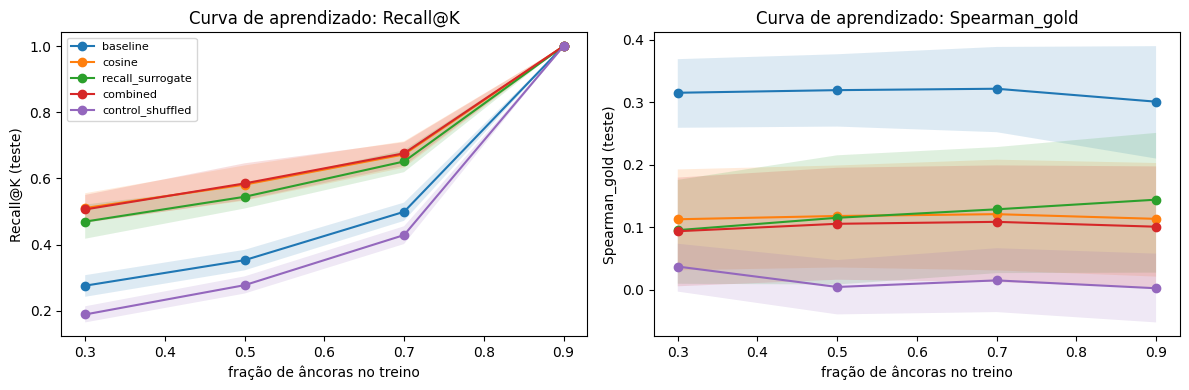

In [ ]:
sig_cols = ["Recall@K", "Spearman", "nDCG@K_gold", "Spearman_gold"]
print("Gap de generalização, Δ = treino − teste (pareado); positivo = o método decora")
gap = paired_delta(D1m[D1m.split.isin(["train", "test"]) & D1m.method.isin(["cosine", "recall_surrogate", "combined", "control_shuffled"])],
                   ["method"], "split", "train", "test", sig_cols)
display(gap.round(3))

print("\nGanho no TESTE sobre a baseline: Δ = método − baseline (Δ > 0 e IC fora de 0 = transferência real)")
dt = deltas_vs(D1m[D1m.split == "test"], ["split"], sig_cols)
display(dt.round(3))

# curva de aprendizado: teste vs fração de âncoras usadas no treino
lc = summarize(D1[D1.split == "test"], ["frac", "method"], ["Recall@K", "Spearman_gold"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["Recall@K", "Spearman_gold"]):
    for m in ["baseline", "cosine", "recall_surrogate", "combined", "control_shuffled"]:
        s = lc[(lc.method == m) & (lc.metric == metric)].sort_values("frac")
        ax.plot(s.frac, s["mean"], marker="o", label=m)
        ax.fill_between(s.frac, s.lo, s.hi, alpha=0.15)
    ax.set_xlabel("fração de âncoras no treino"); ax.set_ylabel(metric + " (teste)")
    ax.set_title(f"Curva de aprendizado: {metric}")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Como ler:** (i) `train ≫ test` para `recall_surrogate`/`combined` confirma que o 1.0 do notebook antigo era memorização; (ii) `control_shuffled` deve ficar próximo da baseline/acaso no teste; (iii) se `combined` supera a baseline **no teste** com IC fora de 0, há transferência genuína de ordenação para âncoras novas; (iv) a curva mostra se mais âncoras ajudam.

# Experimento 2 — Testar diferentes seeds  *(prioridade: muito alta)*

**Pergunta:** o resultado é estável ou depende de sorte? Duas leituras:
- `all_vary`: seed muda split + templates + ruído de inicialização (variabilidade total).
- `split_fixed`: o conjunto de teste é **idêntico**; só treino varia. Aqui também medimos o **Jaccard** entre os top-K previstos de seeds diferentes (os vizinhos escolhidos são sempre os mesmos?).

Distribuição das médias POR SEED (teste)


Recall@K                      Spearman                      Spearman_gold                     
                                 mean    std    min    max     mean    std    min    max          mean    std    min    max
mode        method                                                                                                         
all_vary    baseline            0.499  0.031  0.467  0.547    0.199  0.055  0.139  0.296         0.321  0.041  0.264  0.407
            cosine              0.673  0.059  0.597  0.756    0.587  0.104  0.448  0.720         0.121  0.020  0.095  0.151
            recall_surrogate    0.651  0.046  0.592  0.739    0.493  0.082  0.371  0.623         0.129  0.041  0.069  0.200
            combined            0.676  0.051  0.614  0.758    0.591  0.104  0.438  0.744         0.109  0.023  0.067  0.143
            control_shuffled    0.429  0.026  0.386  0.464    0.011  0.044 -0.062  0.060         0.015  0.060 -0.067  0.098
            teacher_ceiling       NaN    NaN    NaN    NaN      NaN    NaN    NaN    NaN         0.129  0.027  0.097  0.196
split_fixed baseline            0.528  0.006  0.519  0.533    0.244  0.009  0.235  0.264         0.323  0.000  0.323  0.323
            cosine              0.593  0.006  0.581  0.600    0.480  0.023  0.441  0.501         0.085  0.007  0.076  0.095
            recall_surrogate    0.588  0.013  0.567  0.603    0.405  0.019  0.375  0.424         0.071  0.023  0.035  0.095
            combined            0.605  0.018  0.575  0.619    0.494  0.025  0.453  0.519         0.094  0.005  0.086  0.099
            control_shuffled    0.427  0.018  0.406  0.450    0.026  0.040 -0.031  0.073        -0.000  0.059 -0.092  0.086
            teacher_ceiling       NaN    NaN    NaN    NaN      NaN    NaN    NaN    NaN         0.109  0.008  0.101  0.120


Fração de seeds em que o método supera a baseline (Recall@K no teste, all_vary): {'combined': 1.0, 'control_shuffled': 0.0, 'cosine': 1.0, 'recall_surrogate': 1.0}


,Jaccard médio dos top-K entre seeds (split fixo)
baseline,1.000
cosine,0.853
recall_surrogate,0.911
combined,0.882
control_shuffled,0.275


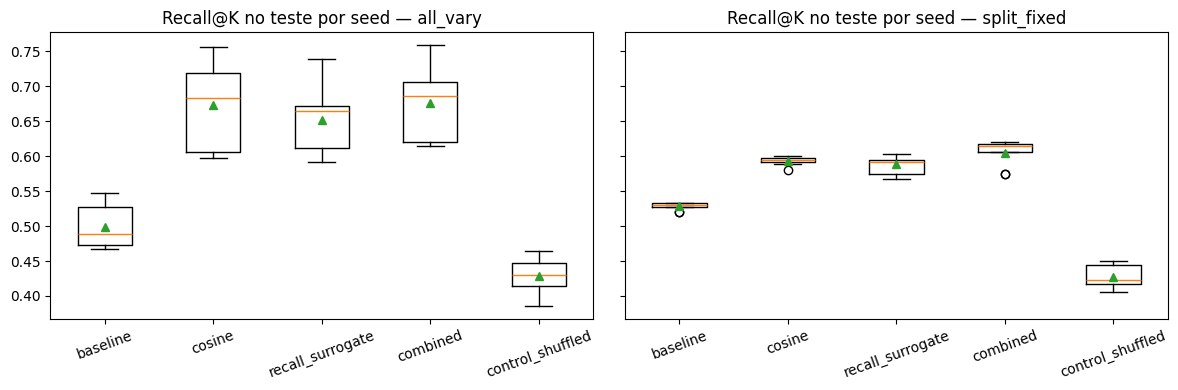

In [ ]:
D2 = DF[(DF.layer == LAYER_MAIN) & (DF.frac == MAIN_FRAC) & (DF.split == "test")]
per_seed = (D2.groupby(["mode", "method", "seed"])[["Recall@K", "Spearman", "Spearman_gold"]].mean().reset_index())
agg = per_seed.groupby(["mode", "method"])[["Recall@K", "Spearman", "Spearman_gold"]].agg(["mean", "std", "min", "max"]).round(3)
print("Distribuição das médias POR SEED (teste)")
display(agg.sort_index(key=lambda idx: idx.map(lambda x: METHOD_ORDER.index(x) if x in METHOD_ORDER else x)))

# taxa de vitória sobre a baseline entre seeds
piv = per_seed[per_seed["mode"] == "all_vary"].pivot(index="seed", columns="method", values="Recall@K")
wins = {m: float((piv[m] > piv["baseline"]).mean()) for m in piv.columns if m not in ("baseline", "teacher_ceiling")}
print("\nFração de seeds em que o método supera a baseline (Recall@K no teste, all_vary):", {k: round(v, 2) for k, v in wins.items()})

def mean_pairwise_jaccard(tag, method):
    seeds = sorted(s for (t, s, m) in TOPK if t == tag and m == method)
    vals = []
    for ti in range(N_T):
        sets = [set(TOPK[(tag, s, method)][ti].tolist()) for s in seeds]
        vals += [len(a & b) / len(a | b) for a, b in itertools.combinations(sets, 2)]
    return float(np.mean(vals)) if vals else np.nan

jac = pd.DataFrame({"Jaccard médio dos top-K entre seeds (split fixo)":
                    {m: mean_pairwise_jaccard("split_fixed", m) for m in ["baseline", "cosine", "recall_surrogate", "combined", "control_shuffled"]}}).round(3)
display(jac)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, mode in zip(axes, ["all_vary", "split_fixed"]):
    sub = per_seed[per_seed["mode"] == mode]
    ms = [m for m in METHOD_ORDER if m in set(sub.method) and m != "teacher_ceiling"]
    ax.boxplot([sub[sub.method == m]["Recall@K"].values for m in ms], showmeans=True)
    ax.set_xticks(range(1, len(ms) + 1)); ax.set_xticklabels(ms, rotation=20)
    ax.set_title(f"Recall@K no teste por seed — {mode}")
plt.tight_layout(); plt.show()

**Como ler:** compare o desvio entre seeds de `all_vary` com o de `split_fixed`. Se o primeiro é bem maior, a variância vem sobretudo do **split de âncoras**, e conclusões com um único split são frágeis. Jaccard próximo de 1 = vizinhos reproduzíveis; o `control_shuffled` mostra o piso (vizinhos sem relação com o professor). A baseline tem Jaccard 1 por ser determinística (ela não é treinada).

# Experimento 3 — Testar novos contextos  *(prioridade: alta)*

Duas partes, de dificuldade crescente:

**3a. Contextos novos do professor.** Os vetores foram treinados com relações extraídas de templates com a palavra no **fim** da frase. Aqui avaliamos contra relações extraídas de **5 contextos novos** (palavra no meio). `teacher_ceiling` mostra o teto: o quanto o próprio professor concorda consigo mesmo entre contextos.

**3b. Uso funcional no GPT-2.** O novo token é colocado em frases de definição que o vetor **nunca viu**:
- *NLL da definição dada a palavra*: o modelo prevê melhor o texto da definição depois do token novo do que depois de um token aleatório? Referência superior: a tokenização original em subtokens.
- *Identificação*: dado “What is the process by which plants…? Answer:”, o modelo atribui mais probabilidade ao token novo certo do que aos outros tokens novos? Acaso = 1/N.

In [ ]:
D3 = D1m[D1m.split.isin(["test", "test_newctx"])]
s3 = summarize(D3, ["split", "method"], ["Recall@K", "nDCG@K", "Spearman", "nDCG@K_gold", "Spearman_gold"])
print("3a — relações do professor em contextos de TREINO (test) vs NOVOS (test_newctx), âncoras de teste")
display(show(s3, ["split", "method"], ["Recall@K", "nDCG@K", "Spearman", "nDCG@K_gold", "Spearman_gold"]))
print("\nGanho sobre a baseline em contextos NOVOS")
display(deltas_vs(D3[D3.split == "test_newctx"], ["split"], ["Recall@K", "Spearman", "Spearman_gold"]).round(3))

3a — relações do professor em contextos de TREINO (test) vs NOVOS (test_newctx), âncoras de teste


metric                                    Recall@K                nDCG@K               Spearman           nDCG@K_gold          Spearman_gold
split       method                                                                                                                          
test        baseline          0.499 [0.472, 0.527]  0.610 [0.571, 0.650]   0.199 [0.140, 0.257]  0.635 [0.578, 0.685]   0.321 [0.252, 0.388]
            cosine            0.673 [0.632, 0.712]  0.859 [0.827, 0.889]   0.587 [0.515, 0.650]  0.489 [0.418, 0.554]   0.121 [0.031, 0.208]
            recall_surrogate  0.651 [0.619, 0.686]  0.807 [0.766, 0.847]   0.493 [0.434, 0.553]  0.493 [0.417, 0.566]   0.129 [0.027, 0.228]
            combined          0.676 [0.638, 0.710]  0.855 [0.821, 0.889]   0.591 [0.518, 0.656]  0.478 [0.409, 0.544]   0.109 [0.012, 0.199]
            control_shuffled  0.429 [0.402, 0.455]  0.512 [0.460, 0.559]  0.011 [-0.036, 0.055]  0.401 [0.360, 0.443]  0.015 [-0.036, 0.066]
            teacher_ceiling                    NaN                   NaN                    NaN  0.484 [0.431, 0.532]   0.129 [0.073, 0.185]
test_newctx baseline          0.470 [0.442, 0.499]  0.612 [0.568, 0.656]   0.151 [0.098, 0.208]  0.635 [0.578, 0.685]   0.321 [0.252, 0.388]
            cosine            0.664 [0.627, 0.700]  0.833 [0.785, 0.878]   0.551 [0.477, 0.617]  0.489 [0.418, 0.554]   0.121 [0.031, 0.208]
            recall_surrogate  0.648 [0.606, 0.694]  0.793 [0.745, 0.839]   0.459 [0.393, 0.516]  0.493 [0.417, 0.566]   0.129 [0.027, 0.228]
            combined          0.681 [0.645, 0.717]  0.835 [0.791, 0.880]   0.565 [0.499, 0.627]  0.478 [0.409, 0.544]   0.109 [0.012, 0.199]
            control_shuffled  0.424 [0.401, 0.447]  0.538 [0.483, 0.589]  0.011 [-0.040, 0.059]  0.401 [0.360, 0.443]  0.015 [-0.036, 0.066]
            teacher_ceiling   0.807 [0.769, 0.841]  0.935 [0.898, 0.965]   0.812 [0.749, 0.859]  0.484 [0.431, 0.532]   0.129 [0.073, 0.185]


Ganho sobre a baseline em contextos NOVOS


,método,split,metric,Δ,lo,hi,significativo
0,cosine,test_newctx,Recall@K,0.194,0.149,0.240,True
1,cosine,test_newctx,Spearman,0.400,0.324,0.473,True
2,cosine,test_newctx,Spearman_gold,-0.201,-0.305,-0.100,True
3,recall_surrogate,test_newctx,Recall@K,0.178,0.131,0.227,True
4,recall_surrogate,test_newctx,Spearman,0.308,0.239,0.376,True
5,recall_surrogate,test_newctx,Spearman_gold,-0.193,-0.310,-0.077,True
6,combined,test_newctx,Recall@K,0.210,0.169,0.253,True
7,combined,test_newctx,Spearman,0.414,0.341,0.484,True
8,combined,test_newctx,Spearman_gold,-0.213,-0.322,-0.108,True
9,control_shuffled,test_newctx,Recall@K,-0.046,-0.087,-0.007,True


In [ ]:
# ---------- 3b. teste funcional no receptor ----------
ITEMS = []
for t, w in enumerate(TARGETS):
    suf = student_tok(" " + GLOSS[w] + ".", add_special_tokens=False)["input_ids"]
    w_orig = student_tok(" " + w, add_special_tokens=False)["input_ids"]
    for p in FUNC_PREFIXES:
        ITEMS.append(dict(t=t, pre=student_tok(p, add_special_tokens=False)["input_ids"], w=w_orig, suf=suf))
QA_ITEMS = [(t, student_tok(q.format(g=GLOSS[w]), add_special_tokens=False)["input_ids"])
            for t, w in enumerate(TARGETS) for q in QA_PROMPTS]

def _pad(seqs):
    L = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    att = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s); att[i, :len(s)] = 1
    return ids.to(DEVICE), att.to(DEVICE)

@torch.inference_mode()
def gloss_nll(variant, bs=32):
    """NLL médio por token da definição, dado prefixo + palavra. variant: 'new' (token novo) | 'orig' (subtokens)."""
    seqs, starts = [], []
    for it in ITEMS:
        wi = [NEW_IDS[it["t"]]] if variant == "new" else it["w"]
        seqs.append(it["pre"] + wi + it["suf"]); starts.append(len(it["pre"]) + len(wi))
    out = np.zeros(len(seqs))
    for i in range(0, len(seqs), bs):
        ids, att = _pad(seqs[i:i + bs])
        logp = F.log_softmax(student(input_ids=ids, attention_mask=att).logits.float()[:, :-1], -1)
        tok_lp = logp.gather(2, ids[:, 1:].unsqueeze(-1)).squeeze(-1)
        for b in range(ids.shape[0]):
            out[i + b] = -tok_lp[b, starts[i + b] - 1: len(seqs[i + b]) - 1].mean().item()
    return np.bincount([it["t"] for it in ITEMS], weights=out, minlength=N_T) / len(FUNC_PREFIXES)

@torch.inference_mode()
def identification(bs=32):
    """Rank do token novo correto entre os N_T tokens novos, pelos logits do próximo token."""
    ranks = np.zeros(len(QA_ITEMS))
    for i in range(0, len(QA_ITEMS), bs):
        chunk = QA_ITEMS[i:i + bs]
        ids, att = _pad([c[1] for c in chunk])
        logits = student(input_ids=ids, attention_mask=att).logits.float()
        last = att.sum(1) - 1
        for b, (t, _) in enumerate(chunk):
            l = logits[b, last[b], NEW_IDS]
            ranks[i + b] = int((l > l[t]).sum().item())
    tgt = np.array([c[0] for c in QA_ITEMS])
    acc = np.bincount(tgt, weights=(ranks == 0).astype(float), minlength=N_T) / len(QA_PROMPTS)
    mrr = np.bincount(tgt, weights=1.0 / (ranks + 1), minlength=N_T) / len(QA_PROMPTS)
    return acc, mrr

nll_sub = gloss_nll("orig")
FUNC_ROWS = []
for seed in SEEDS:
    vecs = dict(VECTORS[("all_vary", seed)])
    g = torch.Generator().manual_seed(4000 + seed)
    vecs["random"] = finalize(MU + torch.randn(N_T, HS, generator=g).to(DEVICE)).cpu()   # controle: direção aleatória
    for name, V in vecs.items():
        set_new_rows(V.to(DEVICE))
        nll = gloss_nll("new"); acc, mrr = identification()
        for t in range(N_T):
            FUNC_ROWS.append(dict(seed=seed, method=name, target=TARGETS[t], NLL=nll[t], **{"Acc@1": acc[t], "MRR": mrr[t]}))
    for t in range(N_T):
        FUNC_ROWS.append(dict(seed=seed, method="subwords", target=TARGETS[t], NLL=nll_sub[t], **{"Acc@1": np.nan, "MRR": np.nan}))
DFF = pd.DataFrame(FUNC_ROWS)

F_ORDER = ["subwords", "baseline", "random", "cosine", "recall_surrogate", "combined", "control_shuffled"]
sf = summarize(DFF, ["method"], ["NLL", "Acc@1", "MRR"])
t = fmt(sf, ["method"])[["NLL", "Acc@1", "MRR"]].reindex([m for m in F_ORDER if m in set(DFF.method)])
print("3b — Uso funcional (NLL: menor é melhor; Acc@1/MRR: maior é melhor)")
display(t)
chance_mrr = float(np.mean(1.0 / np.arange(1, N_T + 1)))
print(f"Acaso: Acc@1 = {1/N_T:.3f} | MRR = {chance_mrr:.3f}")

# Δ NLL pareado: método − random  e  método − baseline  (negativo = melhor)
DFF["grupo"] = "todos"
dd = []
for ref in ["random", "baseline"]:
    for m in ["cosine", "recall_surrogate", "combined", "control_shuffled", "subwords"]:
        d = paired_delta(DFF, ["grupo"], "method", m, ref, ["NLL"])
        d.insert(0, "referência", ref); d.insert(0, "método", m)
        dd.append(d.drop(columns=["grupo"]))
print("\nΔ NLL pareado = método − referência (negativo = método melhor que a referência)")
display(pd.concat(dd, ignore_index=True).round(4))

3b — Uso funcional (NLL: menor é melhor; Acc@1/MRR: maior é melhor)


metric,NLL,Acc@1,MRR
method,,,
subwords,"1.817 [1.591, 2.069]",NaN,NaN
baseline,"2.542 [2.262, 2.856]","0.639 [0.486, 0.778]","0.756 [0.647, 0.855]"
random,"3.027 [2.827, 3.250]","0.039 [0.012, 0.074]","0.124 [0.095, 0.159]"
cosine,"2.911 [2.673, 3.162]","0.157 [0.077, 0.255]","0.329 [0.246, 0.417]"
recall_surrogate,"2.947 [2.705, 3.208]","0.091 [0.035, 0.157]","0.221 [0.154, 0.300]"
combined,"2.935 [2.707, 3.185]","0.105 [0.028, 0.193]","0.266 [0.188, 0.348]"
control_shuffled,"3.037 [2.835, 3.262]","0.023 [0.003, 0.052]","0.114 [0.088, 0.148]"


Acaso: Acc@1 = 0.028 | MRR = 0.116

Δ NLL pareado = método − referência (negativo = método melhor que a referência)


,método,referência,metric,comparação,Δ,lo,hi,significativo
0,cosine,random,NLL,cosine − random,-0.1162,-0.2491,0.0205,False
1,recall_surrogate,random,NLL,recall_surrogate − random,-0.0802,-0.2203,0.0667,False
2,combined,random,NLL,combined − random,-0.0919,-0.2296,0.0459,False
3,control_shuffled,random,NLL,control_shuffled − random,0.0103,-0.0564,0.0688,False
4,subwords,random,NLL,subwords − random,-1.2103,-1.3161,-1.1063,True
5,cosine,baseline,NLL,cosine − baseline,0.3685,0.2033,0.5335,True
6,recall_surrogate,baseline,NLL,recall_surrogate − baseline,0.4044,0.2260,0.5872,True
7,combined,baseline,NLL,combined − baseline,0.3928,0.2222,0.5668,True
8,control_shuffled,baseline,NLL,control_shuffled − baseline,0.4950,0.3438,0.6486,True
9,subwords,baseline,NLL,subwords − baseline,-0.7256,-0.8571,-0.5913,True


**Como ler 3b:** `subwords` é a referência prática (o GPT-2 original lendo o termo quebrado em pedaços). Um token novo útil deve ficar **abaixo de `random`** em NLL e **acima do acaso** em Acc@1. Se só a identificação melhorar mas o NLL não, o vetor ganhou uma assinatura distinguível sem ganhar utilidade para continuar o texto. Efeitos pequenos são esperados: o vetor foi ajustado só para relações com âncoras no espaço de embeddings, não para ser usado dentro do transformer.

# Experimento 4 — Comparar camadas do MLP  *(prioridade: alta)*

**Pergunta:** de qual camada do professor a semântica se transfere melhor? Comparar camadas contra a *própria* relação do professor seria injusto (cada camada define uma régua diferente). Por isso a métrica principal é **Spearman contra o gold** (independente de modelo, âncoras de teste), com o `teacher_ceiling` por camada mostrando o quanto a *própria camada* sabe sobre o gold. A razão `combinado / teto` é a eficiência da transferência.

camada 0 (7s)
camada 4 (22s)
camada 8 (36s)
camada 12 (50s)
camada 16 (65s)
camada 20 (79s)
camada 24 (94s)
camada 28 (108s)
camada 32 (123s)
camada 36 (137s)
camada 40 (152s)
camada 44 (166s)
camada 47 (181s)


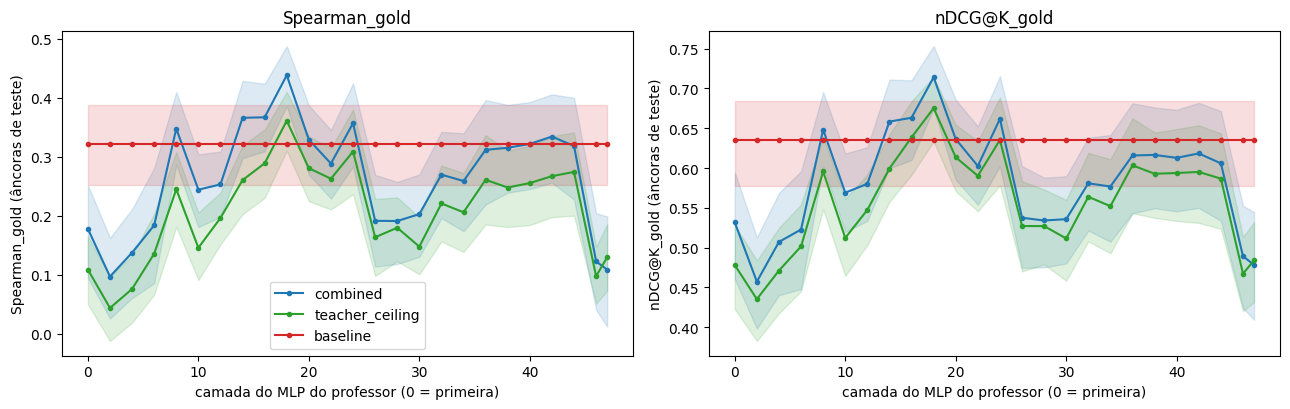

,Spearman_gold,nDCG@K_gold,P@K_gold,eficiência (combinado/teto),"Recall@K (ctx novos, fidelidade)"
layer,,,,,
0,"0.178 [0.094, 0.252]","0.532 [0.460, 0.595]","0.459 [0.394, 0.520]",1.637,"0.610 [0.582, 0.639]"
2,"0.097 [0.026, 0.163]","0.457 [0.398, 0.513]","0.418 [0.359, 0.476]",NaN,"0.683 [0.650, 0.715]"
4,"0.137 [0.060, 0.211]","0.507 [0.440, 0.569]","0.448 [0.389, 0.513]",1.813,"0.598 [0.567, 0.629]"
6,"0.184 [0.086, 0.281]","0.523 [0.448, 0.596]","0.463 [0.393, 0.534]",1.356,"0.550 [0.514, 0.583]"
8,"0.348 [0.287, 0.410]","0.648 [0.603, 0.695]","0.539 [0.484, 0.597]",1.420,"0.611 [0.577, 0.643]"
10,"0.244 [0.181, 0.304]","0.569 [0.520, 0.618]","0.489 [0.431, 0.549]",1.677,"0.620 [0.586, 0.653]"
12,"0.253 [0.198, 0.309]","0.580 [0.534, 0.626]","0.497 [0.444, 0.553]",1.290,"0.580 [0.541, 0.619]"
14,"0.366 [0.298, 0.429]","0.658 [0.600, 0.711]","0.548 [0.491, 0.608]",1.405,"0.606 [0.579, 0.635]"
16,"0.367 [0.309, 0.424]","0.663 [0.610, 0.710]","0.548 [0.487, 0.606]",1.270,"0.628 [0.597, 0.656]"


In [ ]:
LAYER_PRIMARY = "Spearman_gold"
LAYERS = list(range(N_LAYERS)) if N_LAYERS <= 28 else sorted(set(list(range(0, N_LAYERS, 2)) + [N_LAYERS - 1]))
rows, t0 = [], time.time()
for layer in LAYERS:
    for seed in SEEDS:
        rows += run_trial(seed, MAIN_FRAC, layer, [LAYER_OBJECTIVE], tag="layers", control=False)
    if layer % 4 == 0 or layer == LAYERS[-1]:
        print(f"camada {layer} ({time.time()-t0:.0f}s)")
DFL = pd.DataFrame(rows)

DL = DFL[DFL.split == "test"]
sl = summarize(DL, ["layer", "method"], [LAYER_PRIMARY, "nDCG@K_gold", "P@K_gold"])
sl_nc = summarize(DFL[DFL.split == "test_newctx"], ["layer", "method"], ["Recall@K", "Spearman"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, metric, splt in [(axes[0], LAYER_PRIMARY, sl), (axes[1], "nDCG@K_gold", sl)]:
    for m, c in [("combined", "C0"), ("teacher_ceiling", "C2"), ("baseline", "C3")]:
        s = splt[(splt.method == m) & (splt.metric == metric)].sort_values("layer")
        ax.plot(s.layer, s["mean"], marker="o", ms=3, color=c, label=m)
        ax.fill_between(s.layer, s.lo, s.hi, color=c, alpha=0.15)
    ax.set_xlabel("camada do MLP do professor (0 = primeira)"); ax.set_ylabel(metric + " (âncoras de teste)")
    ax.set_title(metric)
axes[0].legend()
plt.tight_layout(); plt.show()

tab = sl[sl.method.isin(["combined", "teacher_ceiling", "baseline"])].pivot_table(index="layer", columns=["metric", "method"], values="mean")
ceil_ = tab[(LAYER_PRIMARY, "teacher_ceiling")]
eff = (tab[(LAYER_PRIMARY, "combined")] / ceil_.where(ceil_ > 0.05)).rename("eficiência (combinado/teto)")  # só se o teto for informativo
out = fmt(sl[(sl.method == "combined")], ["layer"])[[LAYER_PRIMARY, "nDCG@K_gold", "P@K_gold"]].join(eff.round(3))
out["Recall@K (ctx novos, fidelidade)"] = fmt(sl_nc[(sl_nc.method == "combined")], ["layer"])["Recall@K"]
display(out)

In [ ]:
def layer_mat(layer):
    return _mat(DL[(DL.layer == layer) & (DL.method == "combined")], LAYER_PRIMARY)

means = {l: np.nanmean(layer_mat(l).values) for l in LAYERS}
BEST_LAYER = max(means, key=means.get)
Mb = layer_mat(BEST_LAYER)
indist = []
for l in LAYERS:
    if l == BEST_LAYER:
        continue
    Ml = layer_mat(l)
    ri, ci = Mb.index.intersection(Ml.index), Mb.columns.intersection(Ml.columns)
    mean, lo, hi = cluster_bootstrap(Mb.loc[ri, ci].values - Ml.loc[ri, ci].values)
    if lo <= 0 <= hi:
        indist.append(l)
base_ref = float(np.nanmean(_mat(DL[(DL.layer == BEST_LAYER) & (DL.method == "baseline")], LAYER_PRIMARY).values))
print(f"Melhor camada por {LAYER_PRIMARY}: {BEST_LAYER} (média {means[BEST_LAYER]:.3f}; baseline {base_ref:.3f})")
print(f"Camadas estatisticamente indistinguíveis da melhor (IC95% do Δ contém 0): {indist}")
print(f"\n>>> Para repetir os Exp. 1–3 com a camada vencedora, defina MAIN_LAYER = {BEST_LAYER} e rode de novo.")

Melhor camada por Spearman_gold: 18 (média 0.438; baseline 0.321)
Camadas estatisticamente indistinguíveis da melhor (IC95% do Δ contém 0): []

>>> Para repetir os Exp. 1–3 com a camada vencedora, defina MAIN_LAYER = 18 e rode de novo.


**Como ler:** o `teacher_ceiling` mostra onde a informação existe; o `combined` mostra quanto dela chegou ao receptor. Um vão grande entre os dois aponta limite do método de transferência (âncoras, loss, espaço do receptor), não do professor. Como o número de camadas candidatas é grande e as seeds são poucas, trate "melhor camada" como hipótese: o conjunto de camadas indistinguíveis é a conclusão mais honesta.

## Resumo final, verificações de integridade e exportação

In [ ]:
def one(df, **kw):
    q = df
    for k, v in kw.items():
        q = q[q[k] == v]
    return q

def line(label, d):
    if d is None or len(d) == 0:
        return f"  {label}: n/d"
    r = d.iloc[0]
    col = "Δ"
    flag = "SIGNIFICATIVO" if r["significativo"] else "não significativo"
    return f"  {label}: Δ = {r[col]:+.3f}  IC95% [{r['lo']:+.3f}, {r['hi']:+.3f}]  → {flag}"

print("=" * 78)
print(f"RESUMO — φ={PHI} | {cfg.teacher_id} → {cfg.student_id}")
print(f"{N_T} alvos, {N_A} âncoras, {len(SEEDS)} seeds, camada principal {LAYER_MAIN}/{N_LAYERS-1}, K={TOP_K}")
print("=" * 78)

print("\n[1] Generalização (âncoras novas, combined vs baseline)")
print(line("Recall@K   ", dt[(dt["método"] == "combined") & (dt.metric == "Recall@K")]))
print(line("Spearman_gold", dt[(dt["método"] == "combined") & (dt.metric == "Spearman_gold")]))
print(line("Gap treino−teste Recall@K (combined)", gap[(gap.method == "combined") & (gap.metric == "Recall@K")]))
print(line("Controle embaralhado vs baseline, Recall@K", dt[(dt["método"] == "control_shuffled") & (dt.metric == "Recall@K")]))

print("\n[2] Estabilidade entre seeds (Recall@K no teste, combined)")
r = per_seed[(per_seed["mode"] == "all_vary") & (per_seed.method == "combined")]["Recall@K"]
r2 = per_seed[(per_seed["mode"] == "split_fixed") & (per_seed.method == "combined")]["Recall@K"]
print(f"  desvio entre seeds: all_vary = {r.std():.3f} | split_fixed = {r2.std():.3f}")
print(f"  vitórias sobre a baseline: {wins.get('combined', float('nan')):.0%} das seeds | Jaccard split fixo = {jac.iloc[:, 0].get('combined', float('nan')):.2f}")

print("\n[3] Novos contextos")
dnc = deltas_vs(D3[D3.split == "test_newctx"], ["split"], ["Recall@K"])
print(line("3a Recall@K em contextos novos (combined vs baseline)", dnc[dnc["método"] == "combined"]))
fn = DFF.pivot_table(index="method", values=["NLL", "Acc@1"])
dn = pd.concat(dd, ignore_index=True)
print(line("3b NLL da definição (combined − random; negativo = melhor)", dn[(dn["método"] == "combined") & (dn["referência"] == "random")]))
print(f"  3b identificação Acc@1 combined = {fn.loc['combined','Acc@1']:.3f} (acaso {1/N_T:.3f})")

print(f"\n[4] Camadas: melhor = {BEST_LAYER}; indistinguíveis: {indist}")

# --- integridade ---
cur = student.get_input_embeddings().weight[:ORIG_VOCAB].detach().cpu()
change = (cur - old_rows_snapshot).abs().max().item()
print(f"\nIntegridade: maior alteração nas linhas antigas do embedding = {change}")
assert change == 0.0, "Linhas antigas foram alteradas!"
assert sum(p.requires_grad for p in student.parameters()) == 0 and sum(p.requires_grad for p in teacher.parameters()) == 0
print("Parâmetros treináveis nos modelos: 0 (somente os vetores novos foram otimizados, fora do grafo do modelo).")

os.makedirs("results", exist_ok=True)
DF.to_csv("results/exp123_trials.csv", index=False)
DFL.to_csv("results/exp4_layers_trials.csv", index=False)
DFF.to_csv("results/exp3b_functional.csv", index=False)
s1.to_csv("results/exp1_summary.csv", index=False); sl.to_csv("results/exp4_summary.csv", index=False)
json.dump({**asdict(cfg), "layer_main": LAYER_MAIN, "best_layer": int(BEST_LAYER), "top_k": TOP_K, "targets": TARGETS, "anchors": ANCHORS},
          open("results/config.json", "w"), indent=2)
print("Salvo em ./results/")

RESUMO — φ=5 | Qwen/Qwen2.5-14B → openai-community/gpt2-xl
36 alvos, 80 âncoras, 9 seeds, camada principal 47/47, K=10

[1] Generalização (âncoras novas, combined vs baseline)
  Recall@K   : Δ = +0.177  IC95% [+0.127, +0.227]  → SIGNIFICATIVO
  Spearman_gold: Δ = -0.213  IC95% [-0.322, -0.108]  → SIGNIFICATIVO
  Gap treino−teste Recall@K (combined): Δ = +0.324  IC95% [+0.290, +0.362]  → SIGNIFICATIVO
  Controle embaralhado vs baseline, Recall@K: Δ = -0.070  IC95% [-0.112, -0.032]  → SIGNIFICATIVO

[2] Estabilidade entre seeds (Recall@K no teste, combined)
  desvio entre seeds: all_vary = 0.051 | split_fixed = 0.018
  vitórias sobre a baseline: 100% das seeds | Jaccard split fixo = 0.88

[3] Novos contextos
  3a Recall@K em contextos novos (combined vs baseline): Δ = +0.210  IC95% [+0.169, +0.253]  → SIGNIFICATIVO
  3b NLL da definição (combined − random; negativo = melhor): Δ = -0.092  IC95% [-0.230, +0.046]  → não significativo
  3b identificação Acc@1 combined = 0.105 (acaso 0.028)



## Teste de geração (qualitativo, opcional)

Monta os ids à mão (o tokenizador não conhece os tokens novos) e gera com o vetor `combined` da seed 0. Serve só como inspeção; as conclusões vêm dos experimentos acima.

In [ ]:
set_new_rows(VECTORS[("all_vary", 0)]["combined"].to(DEVICE))
@torch.inference_mode()
def gen(prompt_before, t_idx, prompt_after, n=30):
    ids = student_tok(prompt_before, add_special_tokens=False)["input_ids"] + [NEW_IDS[t_idx]] + student_tok(prompt_after, add_special_tokens=False)["input_ids"]
    x = torch.tensor([ids], device=DEVICE)
    out = student.generate(input_ids=x, attention_mask=torch.ones_like(x), max_new_tokens=n, do_sample=False, pad_token_id=PAD_ID)[0].tolist()
    new_map = {i: " " + w for i, w in zip(NEW_IDS, TARGETS)}
    parts, buf = [], []
    for i in out:
        if i in new_map:
            parts.append(student_tok.decode(buf)); buf = []; parts.append(new_map[i])
        else:
            buf.append(i)
    parts.append(student_tok.decode(buf))
    return "".join(parts)

for t in range(min(4, N_T)):
    print("-", gen("In science,", t, " refers to"), "\n")

- In science, photosynthesis refers to the study of the natural world. It is the study of the natural world as it is, not as it might be. It is the study of 

- In science, bioluminescence refers to the study of the natural world. It is the study of the natural world, and the natural world is the universe.

The universe is the 

- In science, thermodynamics refers to the study of the physical world. It is the study of the physical world in its entirety, including the physical world of matter, energy, and space 

- In science, electroencephalography refers to the study of the physical world. In the humanities, it refers to the study of human experience.

The two fields are closely related, but 



In [ ]:
@torch.inference_mode()
def generate(prompt, max_new_tokens=60):
    inputs = student_tok(prompt, return_tensors="pt").to(DEVICE)
    out = student.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=student_tok.eos_token_id, use_cache=True)
    return student_tok.decode(out[0], skip_special_tokens=True)

GENERATION_PROMPTS = {
 "photosynthesis": "Photosynthesis is the biological process in which",
 "bioluminescence": "Bioluminescence is the production of light by",
 "thermodynamics": "Thermodynamics studies the relationships among heat, work, temperature, and",
 "electroencephalography": "Electroencephalography is a method used to record",
}
for w in TARGETS:
    prompt = GENERATION_PROMPTS.get(w, f"In science, {w} is a concept involving")
    print("\n###", w)
    print(generate(prompt, max_new_tokens=55))



### photosynthesis
Photosynthesis is the biological process in which plants use sunlight to convert carbon dioxide and water into sugars. The process is a complex one, involving a number of different chemical reactions.

The process is also a major source of carbon dioxide emissions, which are a major contributor to global warming.

The researchers found

### bioluminescence
Bioluminescence is the production of light by living organisms. It is a form of energy production that is used to communicate, attract mates, and attract predators.

The light produced by bioluminescence is a form of energy production that is used to communicate, attract mates, and attract predators.



### thermodynamics
Thermodynamics studies the relationships among heat, work, temperature, and pressure. The work done by a system is the amount of energy it takes to raise the temperature of a system by one degree Celsius. The temperature of a system is the temperature of the system minus the temperature of the su

## Limitações e próximos passos

- **Gold grosseiro:** domínios escritos à mão (por mim); ele separa "mesma área / área diferente", não grau fino de similaridade. Para publicação, substitua por anotação humana ou benchmark lexical (ex.: WordSim/SimLex adaptado).
- **Ruído com poucas seeds:** com φ pequeno (3 seeds) o bootstrap tem pouca resolução. Prefira φ ≥ 2, ou `OVERRIDES = {"n_seeds": 10}`.
- **Comparações múltiplas:** os IC de 95% não são corrigidos para o grande número de métricas/camadas. Trate achados isolados como indícios.
- **Dependência do gold e do professor:** as âncoras e o gold compartilham o vocabulário de domínio dos alvos; o resultado pode não se estender a palavras de outros domínios.
- **Teste funcional é indireto:** o vetor é otimizado para relações estáticas com âncoras, não para o uso dentro do transformer. Melhorar o NLL exigiria um objetivo que passe pelo modelo (por exemplo, casar estados ocultos do receptor), o que muda a hipótese do projeto.
- **Regularização:** não há termo de ancoragem ao ponto inicial (`||V − init||`). Se o gap treino−teste do Exp. 1 for grande, é o primeiro ajuste a testar.
- **fp16 na T4:** modelos Qwen maiores em fp16 podem gerar valores não finitos; o código detecta e interrompe com mensagem. Nesse caso reduza φ.
- **Estimativa de VRAM:** é aproximada. Se der OOM, reduza `MODEL_SCALE` em 1.